In [66]:
from project_olist.config import PROCESSED_DATA_DIR
import pandas
import seaborn

dataframe_pedidos = pandas.read_csv(PROCESSED_DATA_DIR / "pedidos.csv")
dataframe_avaliacoes = pandas.read_csv(PROCESSED_DATA_DIR / "avaliacoes.csv")

dataframe_pedidos_com_avaliacao = pandas.merge(
    dataframe_pedidos, 
    dataframe_avaliacoes, 
    left_on="id_pedido", 
    right_on="id_pedido", 
    how="inner"
)

dataframe_pedidos_com_avaliacao.info()

<class 'pandas.DataFrame'>
RangeIndex: 99222 entries, 0 to 99221
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   id_pedido                   99222 non-null  str  
 1   id_cliente                  99222 non-null  str  
 2   status_pedido               99222 non-null  str  
 3   dias_para_entrega_estimada  99222 non-null  int64
 4   dias_para_postagem          99222 non-null  int64
 5   dias_para_entrega           99222 non-null  int64
 6   id_avaliacao                99222 non-null  str  
 7   pontuacao                   99222 non-null  int64
 8   tempo_resposta_dias         99222 non-null  int64
dtypes: int64(5), str(4)
memory usage: 6.8 MB


In [67]:
dataframe_pedidos_com_avaliacao = dataframe_pedidos_com_avaliacao.rename(
    columns={
        "pontuacao": "pontuacao_avaliacao",
        "tempo_resposta_dias": "tempo_resposta_dias_avaliacao"
    }
)

dataframe_pedidos_com_avaliacao.info()

<class 'pandas.DataFrame'>
RangeIndex: 99222 entries, 0 to 99221
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   id_pedido                      99222 non-null  str  
 1   id_cliente                     99222 non-null  str  
 2   status_pedido                  99222 non-null  str  
 3   dias_para_entrega_estimada     99222 non-null  int64
 4   dias_para_postagem             99222 non-null  int64
 5   dias_para_entrega              99222 non-null  int64
 6   id_avaliacao                   99222 non-null  str  
 7   pontuacao_avaliacao            99222 non-null  int64
 8   tempo_resposta_dias_avaliacao  99222 non-null  int64
dtypes: int64(5), str(4)
memory usage: 6.8 MB


In [68]:
dataframe_pedidos_com_avaliacao = dataframe_pedidos_com_avaliacao.drop(
    columns=[
        "id_avaliacao"
    ]
)

dataframe_pedidos_com_avaliacao.info()

<class 'pandas.DataFrame'>
RangeIndex: 99222 entries, 0 to 99221
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   id_pedido                      99222 non-null  str  
 1   id_cliente                     99222 non-null  str  
 2   status_pedido                  99222 non-null  str  
 3   dias_para_entrega_estimada     99222 non-null  int64
 4   dias_para_postagem             99222 non-null  int64
 5   dias_para_entrega              99222 non-null  int64
 6   pontuacao_avaliacao            99222 non-null  int64
 7   tempo_resposta_dias_avaliacao  99222 non-null  int64
dtypes: int64(5), str(3)
memory usage: 6.1 MB


In [69]:
dataframe_pedidos_com_avaliacao.describe()

,dias_para_entrega_estimada,dias_para_postagem,dias_para_entrega,pontuacao_avaliacao,tempo_resposta_dias_avaliacao
count,99222.000000,99222.00000,99222.000000,99222.000000,99222.000000
mean,24.408861,3.19662,12.390972,4.086412,2.582300
std,8.827212,3.53379,9.338222,1.347590,9.890624
min,2.000000,0.00000,0.000000,1.000000,0.000000
25%,19.000000,1.00000,7.000000,4.000000,1.000000
50%,24.000000,2.00000,10.000000,5.000000,1.000000
75%,29.000000,4.00000,15.000000,5.000000,3.000000
max,156.000000,126.00000,208.000000,5.000000,518.000000


In [70]:
dataframe_pedidos_com_avaliacao.to_csv(PROCESSED_DATA_DIR / "pedidos_com_avaliacao.csv")

<Axes: xlabel='pontuacao_avaliacao', ylabel='count'>

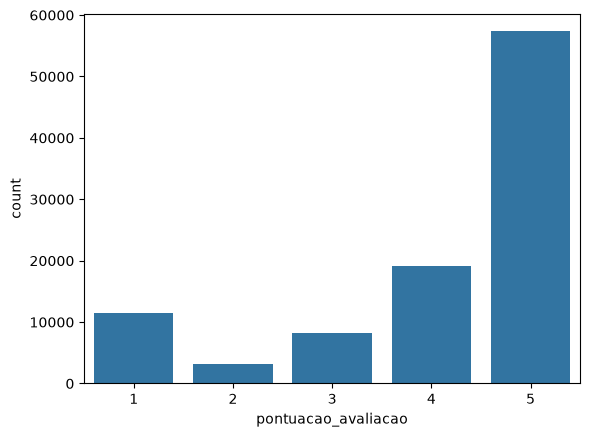

In [71]:
seaborn.countplot(
    data=dataframe_pedidos_com_avaliacao,
    x="pontuacao_avaliacao"
)

In [72]:
dataframe_pedidos_com_avaliacao.head(n=10)

,id_pedido,id_cliente,status_pedido,dias_para_entrega_estimada,dias_para_postagem,dias_para_entrega,pontuacao_avaliacao,tempo_resposta_dias_avaliacao
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,entregue,16,2,8,4,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,entregue,20,2,14,4,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,entregue,27,0,9,5,4
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,entregue,27,4,14,5,2
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,entregue,13,1,3,5,1
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,entregue,23,2,17,4,0
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,faturado,28,2,10,2,0
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,entregue,22,6,10,5,1
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,entregue,42,3,10,1,2
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,entregue,25,12,18,5,1


<Axes: >

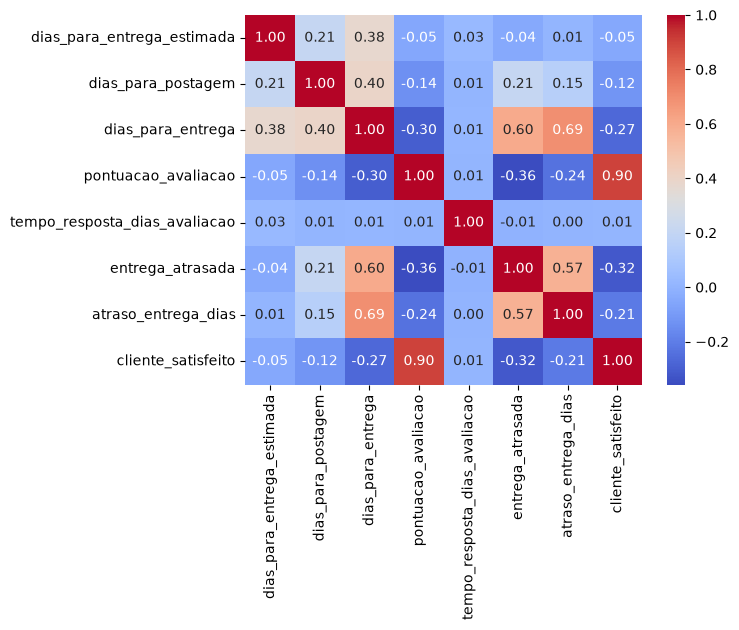

In [74]:
dataframe_pedidos_com_avaliacao["entrega_atrasada"] = dataframe_pedidos_com_avaliacao.apply(
    lambda row: (
        1 if row["dias_para_entrega"] > row["dias_para_entrega_estimada"] 
        else 0
    ),
    axis=1
)

dataframe_pedidos_com_avaliacao["atraso_entrega_dias"] = dataframe_pedidos_com_avaliacao.apply(
    lambda row: (
        0 if row["entrega_atrasada"] == 0 
        else row["dias_para_entrega"] - row["dias_para_entrega_estimada"]
    ),
    axis=1
)

dataframe_pedidos_com_avaliacao["cliente_satisfeito"] = dataframe_pedidos_com_avaliacao.apply(
    lambda row: (
        1 if row["pontuacao_avaliacao"] >= 4
        else 0
    ),
    axis=1
)

seaborn.heatmap(
    data=dataframe_pedidos_com_avaliacao.select_dtypes(include="number").corr(),
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

<Axes: xlabel='dias_para_entrega', ylabel='dias_para_entrega_estimada'>

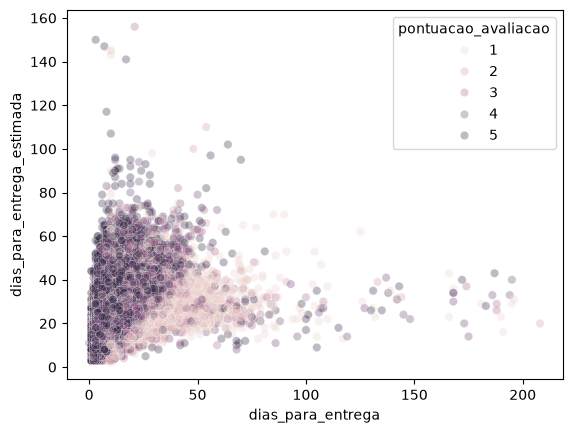

In [79]:
seaborn.scatterplot(
    data=dataframe_pedidos_com_avaliacao,
    x="dias_para_entrega",
    y="dias_para_entrega_estimada",
    hue="pontuacao_avaliacao",
    alpha=0.3
)